In [1]:
import os
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from PIL import Image
import kagglehub

In [2]:
data = []
labels = []

base_dir = kagglehub.dataset_download("kasikrit/att-database-of-faces")
image_shape = (112, 92)

for subject in sorted(os.listdir(base_dir)):
    subject_path = os.path.join(base_dir, subject)
    if os.path.isdir(subject_path):
        for img_name in sorted(os.listdir(subject_path)):
            if img_name.endswith('.pgm'):
                img_path = os.path.join(subject_path, img_name)
                img = imageio.imread(img_path)
                img_array = np.array(img, dtype='float32').flatten()
                data.append(img_array)
                labels.append(int(subject[1:]) - 1)

X = np.array(data)
y = np.array(labels)

print(f"Data Shape: {X.shape}, Number of Classes: {len(set(y))}")

100%|██████████| 3.61M/3.61M [00:00<00:00, 28.9MB/s]

Extracting files...


Data Shape: (400, 10304), Number of Classes: 40


In [3]:
X_centered = X - np.mean(X, axis=0)
cov_matrix = np.cov(X_centered.T)

print("Covariance matrix shape:", cov_matrix.shape)

Covariance matrix shape: (10304, 10304)


In [4]:
pca = PCA(n_components=400)
X_reduced = pca.fit_transform(X)

eigenvalues = pca.explained_variance_
eigenvectors = pca.components_

print("Eigenvectors Shape:", eigenvectors.shape)

Eigenvectors Shape: (400, 10304)


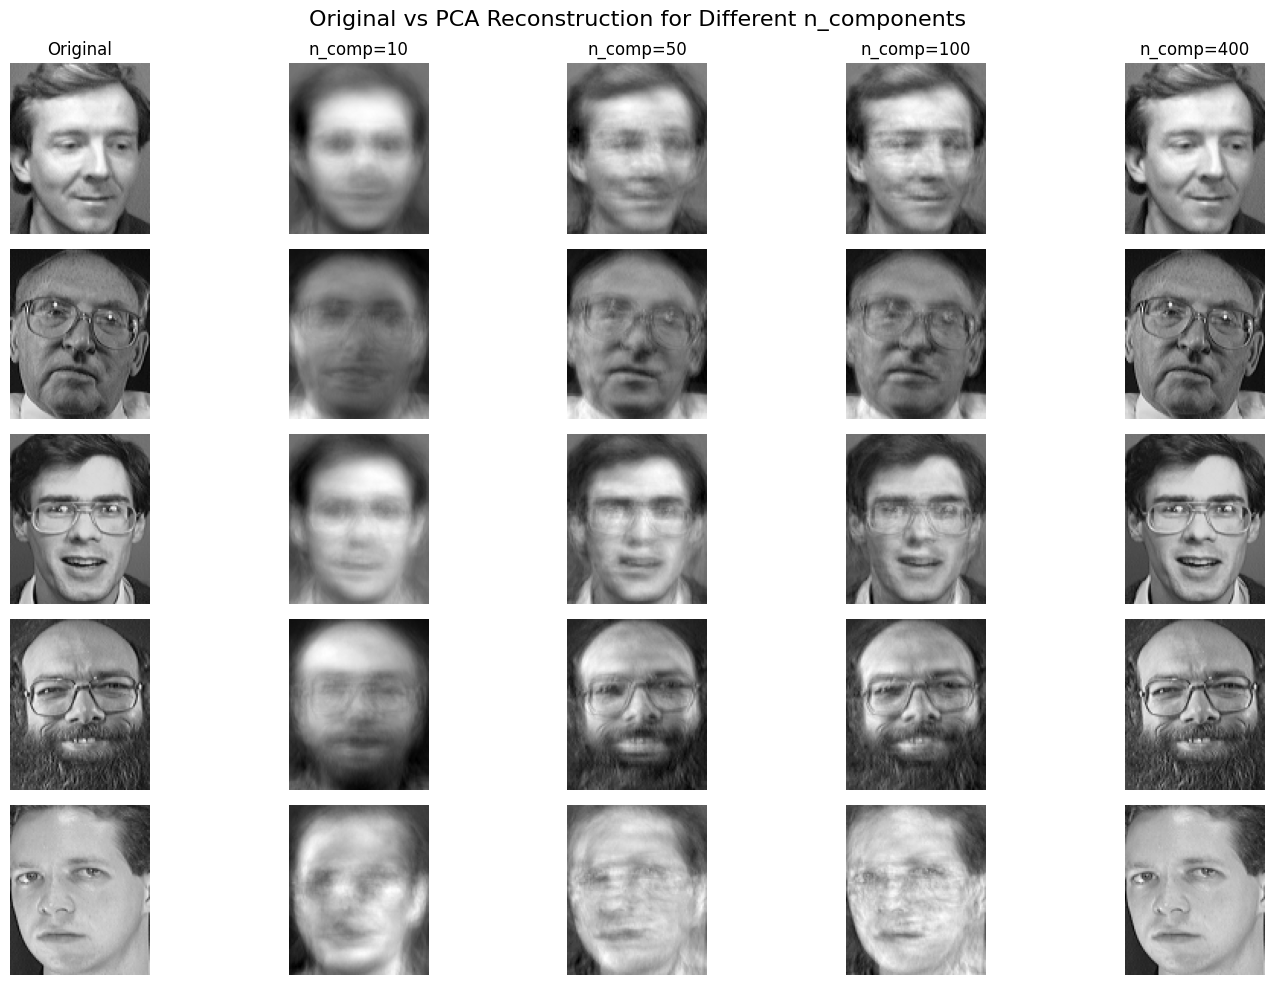

In [5]:
n_comp_values = [10, 50, 100, 400]

unique_classes = np.unique(y)
selected_classes = np.random.choice(unique_classes, size=5, replace=False)

selected_indices = []
for cls in selected_classes:
    class_indices = np.where(y == cls)[0]
    selected_indices.append(np.random.choice(class_indices))

plt.figure(figsize=(15, 10))

for i, idx in enumerate(selected_indices):
    original_image = X[idx]
    plt.subplot(5, len(n_comp_values) + 1, i*(len(n_comp_values) + 1) + 1)
    plt.imshow(original_image.reshape(image_shape), cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title("Original", fontsize=12)

    for j, n_comp in enumerate(n_comp_values):
        pca = PCA(n_components=n_comp)
        X_reduced = pca.fit_transform(X)
        X_reconstructed = pca.inverse_transform(pca.transform(X))
        plt.subplot(5, len(n_comp_values) + 1, i*(len(n_comp_values) + 1) + j + 2)
        plt.imshow(X_reconstructed[idx].reshape(image_shape), cmap='gray')
        plt.axis('off')
        if i == 0:
            plt.title(f"n_comp={n_comp}", fontsize=12)

plt.suptitle("Original vs PCA Reconstruction for Different n_components", fontsize=16)
plt.tight_layout()
plt.show()

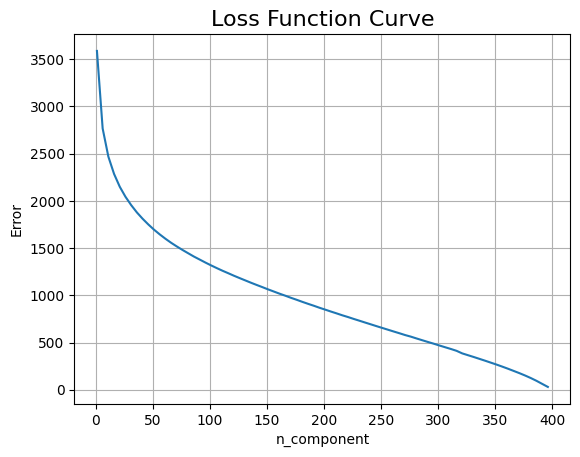

In [ ]:
x_plot = []
y_plot = []
comp_values = []

for i in range(1, 401, 5):
    pca = PCA(n_components=i)
    X_reduced = pca.fit_transform(X)
    X_reconstructed = pca.inverse_transform(X_reduced)

    distances = euclidean_distances(X, X_reconstructed).diagonal()
    reconstruction_error = np.mean(distances)
    comp_values.append(i)

    x_plot.append(i)
    y_plot.append(reconstruction_error)

plt.xlabel('n_component')
plt.ylabel('Error')
plt.title('Loss Function Curve', fontsize=16)
plt.grid()
plt.plot(x_plot, y_plot)
plt.show()

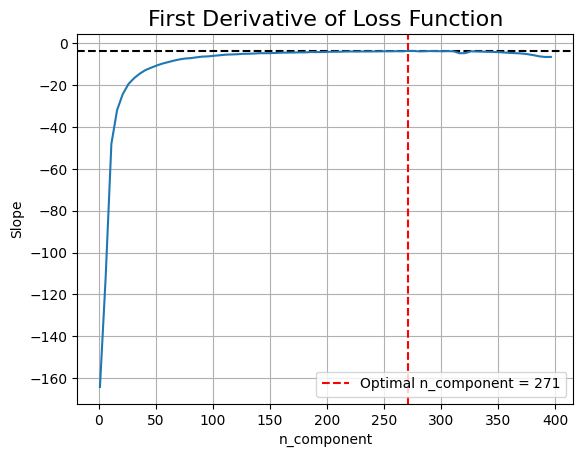

Optimal n_component = 271


In [ ]:
dy = np.gradient(y_plot, x_plot)

zero_indices = np.where(np.isclose(dy, 0, atol=1e-2))[0]

if len(zero_indices) > 0:
    optimal_idx = zero_indices[0]
else:
    optimal_idx = np.argmax(dy)

optimal_n = comp_values[optimal_idx]

plt.axvline(x=optimal_n, color='red', linestyle='--', label=f'Optimal n_component = {optimal_n}')
plt.axhline(y=dy[optimal_idx], color='black', linestyle="--")
plt.xlabel("n_component")
plt.ylabel('Slope')
plt.title('First Derivative of Loss Function', fontsize=16)
plt.grid()
plt.plot(x_plot, dy)
plt.legend()
plt.show()

print(f"Optimal n_component = {optimal_n}")

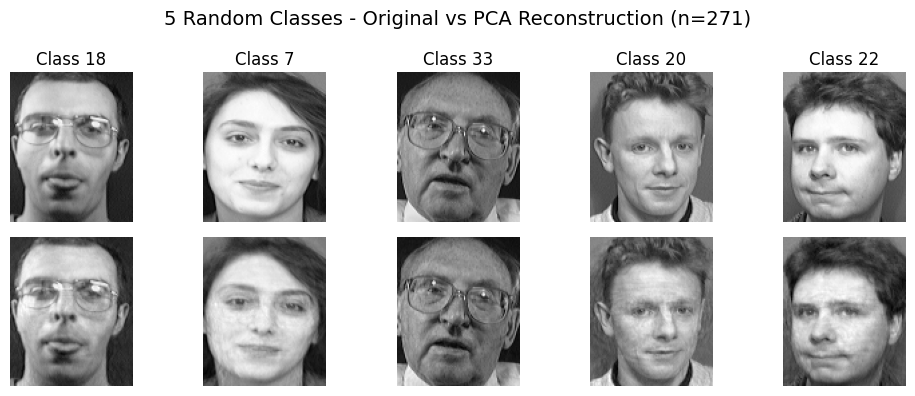

In [ ]:
pca = PCA(n_components=optimal_n)
X_reduced = pca.fit_transform(X)
X_reconstructed = pca.inverse_transform(X_reduced)

unique_classes = np.unique(y)
random_classes = np.random.choice(unique_classes, size=5, replace=False)

selected_indices = []
for cls in random_classes:
    class_indices = np.where(y == cls)[0]
    chosen_idx = np.random.choice(class_indices)
    selected_indices.append(chosen_idx)

plt.figure(figsize=(10, 4))
plt.suptitle(f"5 Random Classes - Original vs PCA Reconstruction (n={optimal_n})", fontsize=14)

for i, idx in enumerate(selected_indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[idx].reshape(image_shape), cmap='gray')
    plt.title(f"Class {y[idx]}")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(X_reconstructed[idx].reshape(image_shape), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()